In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

# Настройка стилей графиков
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

print("Библиотеки успешно загружены!")

Библиотеки успешно загружены!


Первые 5 строк датасета:


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298


Результаты модели регрессии
MSE (Mean Squared Error): 0.4637
R² (Coefficient of Determination): 0.5545


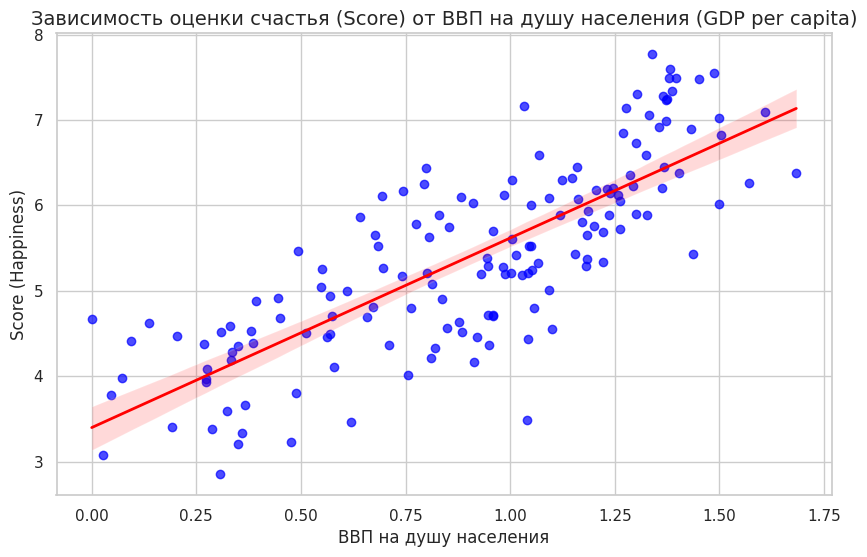

In [12]:

df_happiness = pd.read_csv('world_happiness_report.csv')

print("Первые 5 строк датасета:")
display(df_happiness.head())

# 2. Выбор признаков и целевой переменной
features = ['GDP per capita', 'Social support', 'Healthy life expectancy']
target = 'Score'

X = df_happiness[features]
y = df_happiness[target]

# 3. Разделение на обучающую и тестовую выборки (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Обучение модели линейной регрессии
reg_model = LinearRegression()
reg_model.fit(X_train, y_train)

# 5. Предсказания на тестовой выборке
y_pred = reg_model.predict(X_test)

# 6. Расчет метрик MSE и R²
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Результаты модели регрессии")
print(f"MSE (Mean Squared Error): {mse:.4f}")
print(f"R² (Coefficient of Determination): {r2:.4f}")

# 7. Визуализация зависимости Score от GDP per capita с линией регрессии
plt.figure(figsize=(10, 6))
sns.regplot(
    data=df_happiness,
    x='GDP per capita',
    y='Score',
    scatter_kws={'alpha':0.7, 'color': 'blue'},
    line_kws={'color': 'red', 'linewidth': 2}
)
plt.title('Зависимость оценки счастья (Score) от ВВП на душу населения (GDP per capita)', fontsize=14)
plt.xlabel('ВВП на душу населения', fontsize=12)
plt.ylabel('Score (Happiness)', fontsize=12)
plt.show()

Размер датасета: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes



--- Результаты модели классификации ---
Accuracy (Доля правильных ответов): 0.8068
Precision (Точность для класса 'Yes'): 0.6630
Recall (Полнота для класса 'Yes'): 0.5527


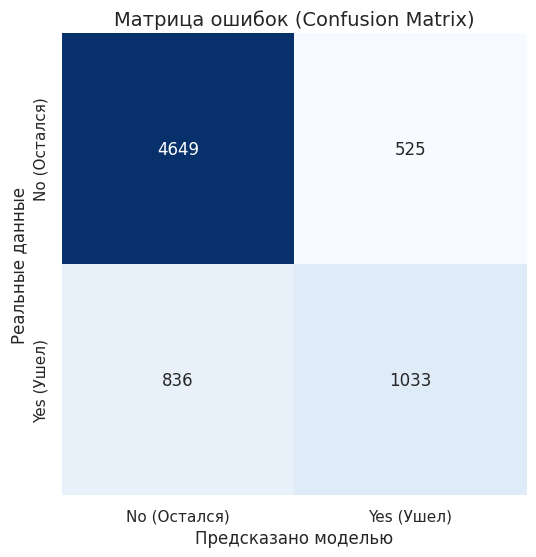

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

df_churn = pd.read_csv('Telco-Customer-Churn.csv')

print("Размер датасета:", df_churn.shape)
display(df_churn.head(3))

if 'customerID' in df_churn.columns:
    df_churn = df_churn.drop('customerID', axis=1)

df_churn['TotalCharges'] = pd.to_numeric(df_churn['TotalCharges'], errors='coerce')
df_churn['TotalCharges'].fillna(df_churn['TotalCharges'].median(), inplace=True)

df_churn['Churn'] = df_churn['Churn'].map({'Yes': 1, 'No': 0})

# Преобразуем категориальные признаки в бинарные с помощью One-Hot Encoding
df_churn_encoded = pd.get_dummies(df_churn, drop_first=True)

# 3. Признаки (X) и целевая переменная (y) для всего датасета
X_class = df_churn_encoded.drop('Churn', axis=1)
y_class = df_churn_encoded['Churn']

# 4. Стандартизация всех данных
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_class)

# 5. Обучение модели логистической регрессии на ВСЕХ данных
log_model = LogisticRegression(max_iter=10000, random_state=42)
log_model.fit(X_scaled, y_class)

# 6. Предсказания на всей выборке (для схождения с Orange)
y_pred_c = log_model.predict(X_scaled)

# 7. Расчет метрик
acc = accuracy_score(y_class, y_pred_c)
precision = precision_score(y_class, y_pred_c)
recall = recall_score(y_class, y_pred_c)

print(f"\nРезультаты модели классификации")
print(f"Accuracy (Доля правильных ответов): {acc:.4f}")
print(f"Precision (Точность для класса 'Yes'): {precision:.4f}")
print(f"Recall (Полнота для класса 'Yes'): {recall:.4f}")

# 8. Построение матрицы ошибок (Confusion Matrix)
cm = confusion_matrix(y_class, y_pred_c)
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No (Остался)', 'Yes (Ушел)'],
            yticklabels=['No (Остался)', 'Yes (Ушел)'])
plt.title('Матрица ошибок (Confusion Matrix)', fontsize=14)
plt.xlabel('Предсказано моделью', fontsize=12)
plt.ylabel('Реальные данные', fontsize=12)
plt.show()